# Credit default risk: from raw repayment history to a lending decision

**Question.** Given six months of a credit card customer's repayment behaviour, how likely are they to default next month, and how should a lender turn that probability into an approve or decline decision?

**Why it matters.** Lenders everywhere face the same trade-off. Approve too freely and defaults eat the profit. Decline too freely and creditworthy people are shut out of credit they could have repaid. A good risk model moves both errors down at once. It also has to be explainable and fair, because lending decisions are regulated (for example by the Equal Credit Opportunity Act in the United States).

**Data.** [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) from the UCI Machine Learning Repository: 30,000 real credit card customers of a bank in Taiwan, April to September 2005, with the outcome observed in October 2005 (Yeh and Lien, 2009).

**What this notebook does**

1. Loads and cleans the data
2. Explores what separates defaulters from non-defaulters
3. Builds behavioural features and deliberately leaves demographics out
4. Trains a logistic regression and a gradient boosted model
5. Evaluates them with the metrics credit risk teams use (AUROC, Gini, KS, calibration)
6. Converts probabilities to a credit score and finds the profit-maximising cutoff
7. Explains the model and audits it for disparate outcomes
8. Exports the model for the live dashboard

## 1. Setup

In [1]:
import io
import json
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

## 2. Load the data

In [2]:
URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
xls_path = RAW / "default of credit card clients.xls"
if not xls_path.exists():
    zipfile.ZipFile(io.BytesIO(requests.get(URL, timeout=120).content)).extractall(RAW)

raw = pd.read_excel(xls_path, header=1)
raw = raw.rename(columns={"default payment next month": "default", "PAY_0": "PAY_1"}).drop(columns="ID")
print(f"{len(raw):,} customers, default rate {raw['default'].mean():.1%}")
raw.head(3)

30,000 customers, default rate 22.1%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


**Columns**

| Column | Meaning |
|---|---|
| `LIMIT_BAL` | Credit limit in New Taiwan dollars |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographics |
| `PAY_1` to `PAY_6` | Repayment status in each of the last six months (`PAY_1` is the most recent). -2 no balance, -1 paid in full, 0 minimum paid (revolving), 1 to 9 months behind |
| `BILL_AMT1` to `BILL_AMT6` | Statement balance in each month |
| `PAY_AMT1` to `PAY_AMT6` | Amount paid in each month |
| `default` | 1 if the customer defaulted the following month |

The source column `PAY_0` is renamed to `PAY_1` so the numbering is consistent.

## 3. Data quality checks

In [3]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("EDUCATION codes:", dict(raw["EDUCATION"].value_counts().sort_index()))
print("MARRIAGE codes: ", dict(raw["MARRIAGE"].value_counts().sort_index()))

Missing values: 0
Duplicate rows: 35
EDUCATION codes: {0: np.int64(14), 1: np.int64(10585), 2: np.int64(14030), 3: np.int64(4917), 4: np.int64(123), 5: np.int64(280), 6: np.int64(51)}
MARRIAGE codes:  {0: np.int64(54), 1: np.int64(13659), 2: np.int64(15964), 3: np.int64(323)}


There are no missing values, but `EDUCATION` contains codes 0, 5 and 6 and `MARRIAGE` contains 0, none of which are in the data dictionary. They are grouped into "Other". The exact duplicate rows are dropped: identical values across 24 columns are far more likely to be repeated records than different people.

In [4]:
df = raw.drop_duplicates().copy()
df["education"] = df["EDUCATION"].map({1: "Graduate school", 2: "University", 3: "High school"}).fillna("Other")
df["sex"] = df["SEX"].map({1: "Male", 2: "Female"})
df["age_band"] = pd.cut(df["AGE"], [0, 29, 39, 49, 120], labels=["Under 30", "30 to 39", "40 to 49", "50 and over"])
PAY = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAID = [f"PAY_AMT{i}" for i in range(1, 7)]
base_rate = df["default"].mean()
print(f"{len(df):,} customers after cleaning, default rate {base_rate:.2%}")

29,965 customers after cleaning, default rate 22.13%


## 4. Exploratory analysis

### Repayment status is the dominant signal

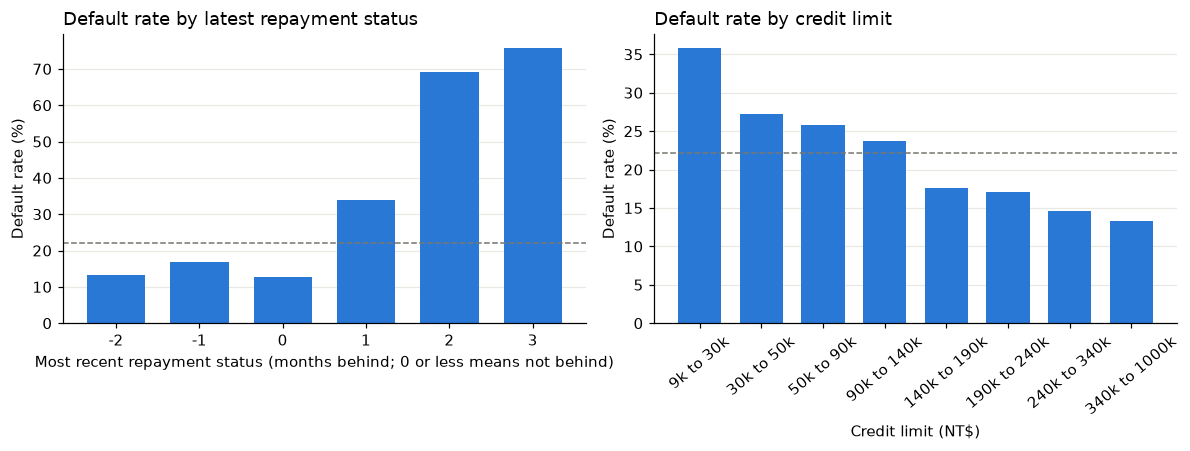

In [5]:
def rate_by(column, min_n=100):
    table = df.groupby(column, observed=True)["default"].agg(rate="mean", customers="size")
    return table[table["customers"] >= min_n]


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
status = rate_by("PAY_1")
axes[0].bar(status.index.astype(str), status["rate"] * 100, color=BLUE, width=0.7)
axes[0].axhline(base_rate * 100, color=GREY, ls="--", lw=1)
axes[0].set(xlabel="Most recent repayment status (months behind; 0 or less means not behind)", ylabel="Default rate (%)")
axes[0].set_title("Default rate by latest repayment status", loc="left")

limit = df.assign(limit_band=pd.qcut(df["LIMIT_BAL"], 8, duplicates="drop")).groupby("limit_band", observed=True)["default"].mean()
axes[1].bar([f"{int(i.left / 1000)}k to {int(i.right / 1000)}k" for i in limit.index], limit.values * 100, color=BLUE, width=0.7)
axes[1].axhline(base_rate * 100, color=GREY, ls="--", lw=1)
axes[1].set(xlabel="Credit limit (NT$)", ylabel="Default rate (%)")
axes[1].set_title("Default rate by credit limit", loc="left")
axes[1].tick_params(axis="x", rotation=40)
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

* A customer who is already two or more months behind defaults at several times the average rate. One who paid in full or made the minimum payment defaults far less often.
* Customers with low credit limits default more. The limit reflects the bank's own earlier assessment of the customer, so it carries information.

### Demographics

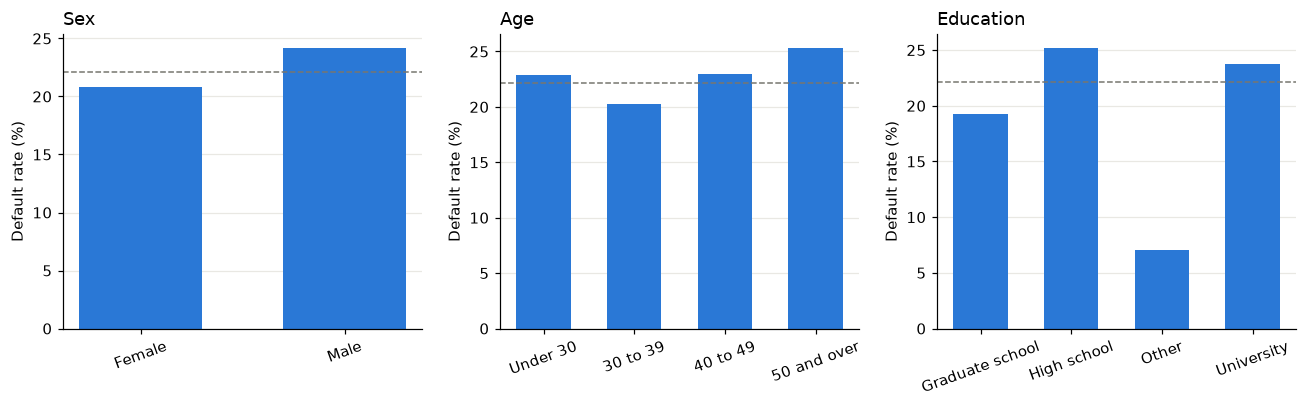

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, column, title in zip(axes, ["sex", "age_band", "education"], ["Sex", "Age", "Education"]):
    table = rate_by(column)
    ax.bar(table.index.astype(str), table["rate"] * 100, color=BLUE, width=0.6)
    ax.axhline(base_rate * 100, color=GREY, ls="--", lw=1)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Default rate (%)")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Default rates differ somewhat by sex, age and education. That is precisely why these variables need care: a model could use them as shortcuts, and in many jurisdictions using sex or marital status in a credit decision is unlawful.

**Design decision: the model is not given sex, marital status, age or education.** It only sees how the customer has handled the account. Demographics are held back and used at the end to audit the outcomes. Section 7 checks how much accuracy this costs.

## 5. Feature engineering

The raw monthly columns are turned into the quantities a credit analyst would ask about:

| Feature | Definition | Why |
|---|---|---|
| `max_delay` | Worst repayment status over six months | Severity of delinquency |
| `months_late` | Number of months with a late payment | Persistence of delinquency |
| `util_latest` | Latest bill divided by credit limit | How stretched the customer is now |
| `util_mean` | Average bill divided by credit limit | How stretched over time |
| `bill_trend` | Change in bill over six months, as a share of the limit | Is debt growing? |
| `pay_ratio` | Total paid divided by total billed | Is the customer paying the debt down? |
| `last_pay_ratio` | Last payment divided by the previous statement | Most recent payment effort |

Ratios are capped so a handful of extreme accounts (for example a tiny bill and a large payment) do not dominate.

In [7]:
def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["limit"] = d["LIMIT_BAL"]
    for i, column in enumerate(PAY, start=1):
        f[f"status_{i}"] = d[column]
    f["max_delay"] = d[PAY].max(axis=1)
    f["months_late"] = (d[PAY] >= 1).sum(axis=1)
    f["util_latest"] = (d["BILL_AMT1"] / d["LIMIT_BAL"]).clip(-0.5, 2)
    f["util_mean"] = (d[BILL].mean(axis=1) / d["LIMIT_BAL"]).clip(-0.5, 2)
    f["bill_trend"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-2, 2)
    f["pay_ratio"] = (d[PAID].sum(axis=1) / d[BILL].sum(axis=1).clip(lower=1)).clip(0, 2)
    f["last_pay_ratio"] = (d["PAY_AMT1"] / d["BILL_AMT2"].clip(lower=1)).clip(0, 2)
    f["last_payment"] = d["PAY_AMT1"]
    return f


X = build_features(df)
y = df["default"]
demo = pd.get_dummies(df[["sex", "education"]], dtype=int).assign(age=df["AGE"], married=(df["MARRIAGE"] == 1).astype(int))
X.describe().T[["mean", "min", "50%", "max"]].round(2)

,mean,min,50%,max
limit,167442.01,10000.00,140000.00,1000000.0
status_1,-0.02,-2.00,0.00,8.0
status_2,-0.13,-2.00,0.00,8.0
status_3,-0.16,-2.00,0.00,8.0
status_4,-0.22,-2.00,0.00,8.0
status_5,-0.26,-2.00,0.00,8.0
status_6,-0.29,-2.00,0.00,8.0
max_delay,0.44,-2.00,0.00,8.0
months_late,0.83,0.00,0.00,6.0
util_latest,0.42,-0.50,0.32,2.0


## 6. Split

60 percent train, 20 percent validation (for early stopping), 20 percent test. The test set is used once, at the end.

In [8]:
idx_train, idx_rest = train_test_split(df.index, test_size=0.4, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, stratify=y.loc[idx_rest], random_state=SEED)
X_train, X_val, X_test = X.loc[idx_train], X.loc[idx_val], X.loc[idx_test]
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]
print(len(X_train), len(X_val), len(X_test), "customers; default rates", round(y_train.mean(), 4), round(y_val.mean(), 4), round(y_test.mean(), 4))

17979 5993 5993 customers; default rates 0.2213 0.2213 0.2213


## 7. Models

* **Logistic regression** is the traditional scorecard model: transparent and easy to defend to a regulator.
* **Gradient boosted trees** capture interactions, for example that high utilisation is much more worrying when the customer is also behind on payments.

The boosted model is trained with **monotonic constraints**: more months late or a worse repayment status can never lower the predicted risk, and paying a larger share of the bill can never raise it. This costs very little accuracy and guarantees the model never gives a customer a perverse reason for a decline, which matters when lenders must explain adverse decisions.

In [9]:
def fit_gbm(train_x, train_y, val_x, val_y, monotone=None):
    model = xgb.XGBClassifier(
        n_estimators=800, learning_rate=0.03, max_depth=4, min_child_weight=20, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=5.0, eval_metric="logloss", early_stopping_rounds=50,
        monotone_constraints=monotone, random_state=SEED, n_jobs=4,
    )
    return model.fit(train_x, train_y, eval_set=[(val_x, val_y)], verbose=False)


MONOTONE = {c: 0 for c in X.columns}
MONOTONE.update({f"status_{i}": 1 for i in range(1, 7)})
MONOTONE.update({"max_delay": 1, "months_late": 1, "pay_ratio": -1, "last_pay_ratio": -1})
monotone = "(" + ",".join(str(MONOTONE[c]) for c in X.columns) + ")"

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)
gbm = fit_gbm(X_train, y_train, X_val, y_val, monotone)
gbm_free = fit_gbm(X_train, y_train, X_val, y_val)

X_demo = pd.concat([X, demo], axis=1)
gbm_demo = fit_gbm(X_demo.loc[idx_train], y_train, X_demo.loc[idx_val], y_val)

p_logit = logit.predict_proba(X_test)[:, 1]
p_gbm = gbm.predict_proba(X_test)[:, 1]
p_free = gbm_free.predict_proba(X_test)[:, 1]
p_demo = gbm_demo.predict_proba(X_demo.loc[idx_test])[:, 1]

## 8. Evaluation

Credit risk teams report three ranking metrics:

* **AUROC**: probability that a random defaulter is scored riskier than a random non-defaulter.
* **Gini** = 2 × AUROC − 1. The same information on a 0 to 1 scale.
* **KS statistic**: the largest gap between the cumulative score distributions of defaulters and non-defaulters. It shows how well a single cutoff can separate the two.

And one for the probabilities themselves: the **Brier score** (lower is better), with a calibration plot.

In [10]:
def ks_statistic(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))


rows = []
for name, p in [("Logistic regression", p_logit), ("Gradient boosting, monotonic (chosen)", p_gbm),
                ("Gradient boosting, unconstrained", p_free), ("Gradient boosting + demographics", p_demo)]:
    auc = roc_auc_score(y_test, p)
    rows.append({"model": name, "AUROC": auc, "Gini": 2 * auc - 1, "KS": ks_statistic(y_test, p), "Brier": brier_score_loss(y_test, p)})
metrics = pd.DataFrame(rows).set_index("model")
metrics.round(4)

,AUROC,Gini,KS,Brier
model,,,,
Logistic regression,0.7529,0.5058,0.4083,0.1410
"Gradient boosting, monotonic (chosen)",0.7872,0.5743,0.4259,0.1336
"Gradient boosting, unconstrained",0.7894,0.5788,0.4316,0.1333
Gradient boosting + demographics,0.7904,0.5808,0.4385,0.1331


Three things to read from this table:

1. The boosted model beats logistic regression, so there are interactions worth capturing.
2. The monotonic constraints cost almost nothing compared with the unconstrained model.
3. Adding sex, age, education and marital status barely changes the result. **Behaviour already contains the signal, so leaving demographics out is close to free.**

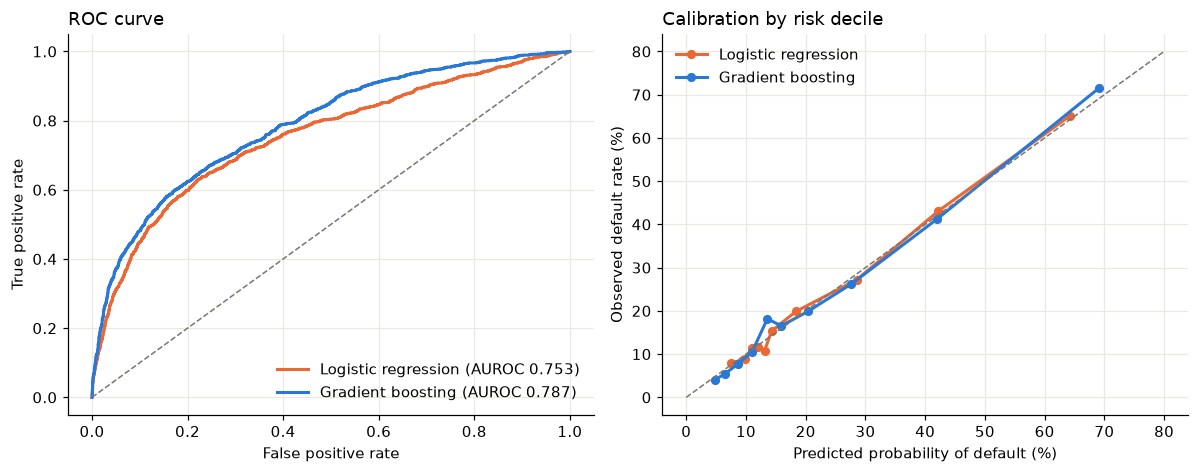

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name, p, color in [("Logistic regression", p_logit, ORANGE), ("Gradient boosting", p_gbm, BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUROC {roc_auc_score(y_test, p):.3f})")
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred * 100, frac * 100, "o-", color=color, lw=2, ms=5, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[0].set_title("ROC curve", loc="left")
axes[0].legend(frameon=False)
axes[1].plot([0, 80], [0, 80], color=GREY, ls="--", lw=1)
axes[1].set(xlabel="Predicted probability of default (%)", ylabel="Observed default rate (%)")
axes[1].set_title("Calibration by risk decile", loc="left")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

The boosted model's points sit on the diagonal across the whole range: when it says 40 percent, about 40 percent of those customers default. That is what allows the probability to be used directly in a profit calculation.

## 9. From probability to credit score

Lenders rarely show a probability. They show a score where higher is better and a fixed number of points doubles the odds of repaying. The standard scaling is used here:

* a score of **600** corresponds to odds of 10 to 1 of repaying (about 9 percent probability of default)
* every **50 points** doubles the odds

so `score = 600 + 50 × log2(odds of repaying / 10)`.

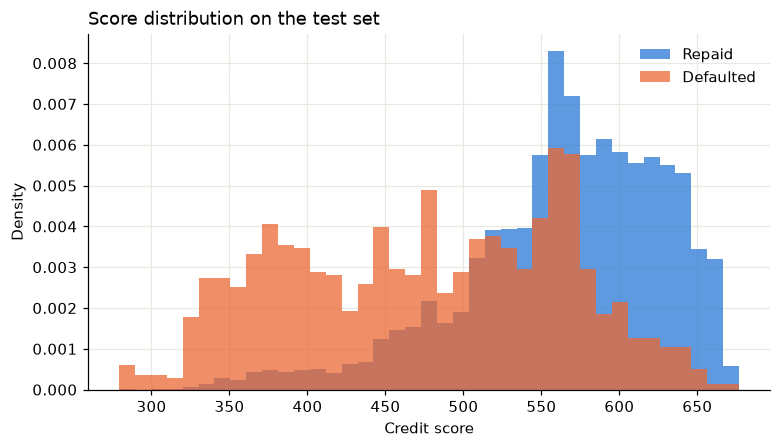

,customers,default_rate,share_of_customers
band,,,
Below 450,809,0.654,0.135
450 to 499,607,0.356,0.101
500 to 549,1122,0.206,0.187
550 to 599,1826,0.145,0.305
600 to 649,1336,0.056,0.223
650 and above,293,0.034,0.049


In [12]:
def to_score(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return 600 + 50 * np.log2(((1 - p) / p) / 10)


scores = to_score(p_gbm)
fig, ax = plt.subplots()
bins = np.linspace(scores.min(), scores.max(), 40)
ax.hist(scores[y_test.values == 0], bins=bins, color=BLUE, alpha=0.75, label="Repaid", density=True)
ax.hist(scores[y_test.values == 1], bins=bins, color=ORANGE, alpha=0.75, label="Defaulted", density=True)
ax.set(xlabel="Credit score", ylabel="Density")
ax.set_title("Score distribution on the test set", loc="left")
ax.legend(frameon=False)
plt.show()

bands = pd.cut(scores, [0, 450, 500, 550, 600, 650, 1000], labels=["Below 450", "450 to 499", "500 to 549", "550 to 599", "600 to 649", "650 and above"])
band_table = pd.DataFrame({"band": bands, "default": y_test.values}).groupby("band", observed=True)["default"].agg(customers="size", default_rate="mean")
band_table["share_of_customers"] = band_table["customers"] / band_table["customers"].sum()
band_table.round(3)

## 10. Choosing the cutoff: a profit view

Accuracy is not the business objective. Profit is. Use a simple unit model:

* a customer who repays earns the lender **1 unit** of profit
* a customer who defaults costs **L units** (the loss is several times the margin on a good account)

The lender should approve a customer when the expected profit is positive, which means approving when the probability of default is below `1 / (1 + L)`. With L = 5, that break-even probability is 16.7 percent.

The chart shows total profit on the test set for every possible cutoff, compared with approving everyone.

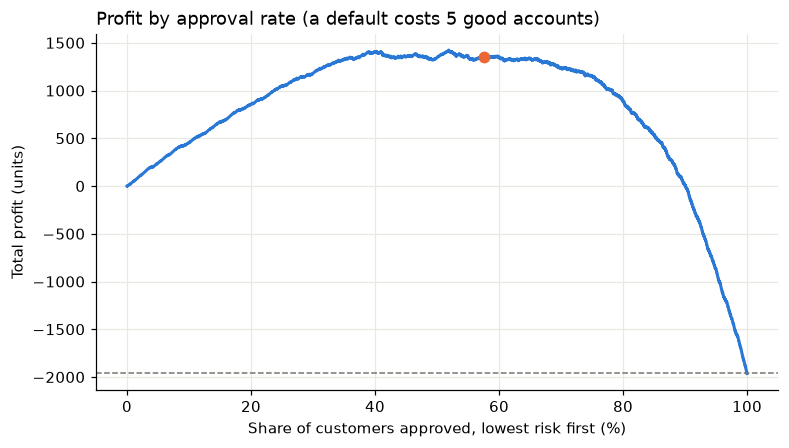

Approve everyone:            profit -1,963 units, default rate 22.1%
Approve below 16.7% risk:    profit 1,355 units, approval rate 57.7%, default rate among approved 10.1%
Best cutoff in hindsight:    profit 1,424 units at approval rate 51.9%


In [13]:
LOSS = 5
order = np.argsort(p_gbm)
sorted_y = y_test.values[order]
sorted_p = p_gbm[order]
profit_curve = np.cumsum(np.where(sorted_y == 1, -LOSS, 1))
approved = np.arange(1, len(sorted_y) + 1)
best = int(np.argmax(profit_curve))
breakeven = 1 / (1 + LOSS)
at_breakeven = int(np.searchsorted(sorted_p, breakeven))

fig, ax = plt.subplots()
ax.plot(approved / len(approved) * 100, profit_curve, color=BLUE, lw=2)
ax.axhline(profit_curve[-1], color=GREY, ls="--", lw=1)
ax.scatter([at_breakeven / len(approved) * 100], [profit_curve[at_breakeven - 1]], color=ORANGE, zorder=3, s=45)
ax.set(xlabel="Share of customers approved, lowest risk first (%)", ylabel="Total profit (units)")
ax.set_title(f"Profit by approval rate (a default costs {LOSS} good accounts)", loc="left")
plt.show()

print(f"Approve everyone:            profit {profit_curve[-1]:,} units, default rate {sorted_y.mean():.1%}")
print(f"Approve below {breakeven:.1%} risk:    profit {profit_curve[at_breakeven - 1]:,} units, approval rate {at_breakeven / len(approved):.1%}, "
      f"default rate among approved {sorted_y[:at_breakeven].mean():.1%}")
print(f"Best cutoff in hindsight:    profit {profit_curve[best]:,} units at approval rate {(best + 1) / len(approved):.1%}")

Approving everyone loses money, because one default wipes out the profit on five good accounts. The break-even cutoff, set from the unit economics alone without looking at test outcomes, captures about 95 percent of the profit of the best cutoff found in hindsight. That only happens when the probabilities are well calibrated, and it means the lender can set policy from the model's probabilities directly instead of searching for a threshold.

## 11. What drives the predictions?

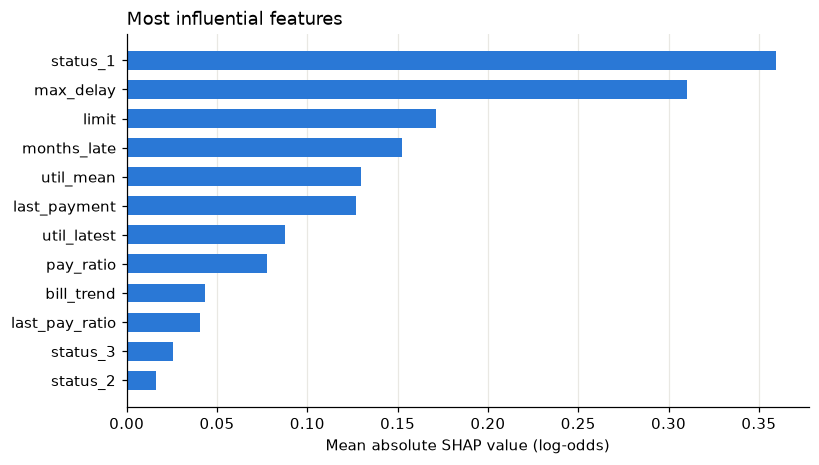

In [14]:
contrib = gbm.get_booster()[: gbm.best_iteration + 1].predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=X.columns).sort_values(ascending=False)
top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top.index, top.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title("Most influential features", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

Recent repayment status and the worst delay in six months dominate, followed by the credit limit, how much of the bill the customer pays, and utilisation. All of these are things a customer can act on, which makes decline reasons meaningful ("two late payments in the last six months") instead of opaque.

## 12. Fairness audit

The model never saw sex, age or education, but it could still treat groups differently through correlated behaviour. Apply the break-even cutoff and compare, for each group:

* **approval rate**: who gets credit
* **default rate among approved**: whether approvals are equally sound
* **predicted against observed default**: whether risk is systematically over or under stated for the group

A common screening rule is the **four-fifths rule**: the approval rate of any group should be at least 80 percent of the highest group's rate.

In [15]:
audit = df.loc[idx_test, ["sex", "age_band", "education"]].assign(y=y_test.values, p=p_gbm, approved=p_gbm < breakeven)
rows = []
for column in ["sex", "age_band", "education"]:
    for level, group in audit.groupby(column, observed=True):
        if len(group) < 100:
            continue
        rows.append({"attribute": column, "group": str(level), "customers": len(group), "approval_rate": group["approved"].mean(),
                     "default_rate_approved": group.loc[group["approved"], "y"].mean(), "observed_default": group["y"].mean(),
                     "predicted_default": group["p"].mean(), "auroc": roc_auc_score(group["y"], group["p"])})
fairness = pd.DataFrame(rows)
fairness["approval_ratio_to_highest"] = fairness["approval_rate"] / fairness.groupby("attribute")["approval_rate"].transform("max")
fairness.round(3)

,attribute,group,customers,approval_rate,default_rate_approved,observed_default,predicted_default,auroc,approval_ratio_to_highest
0,sex,Female,3607,0.590,0.083,0.203,0.212,0.803,1.000
1,sex,Male,2386,0.556,0.130,0.249,0.232,0.765,0.942
2,age_band,Under 30,1925,0.540,0.088,0.214,0.233,0.793,0.903
3,age_band,30 to 39,2227,0.599,0.098,0.203,0.206,0.782,1.000
4,age_band,40 to 49,1307,0.598,0.129,0.253,0.213,0.775,1.000
5,age_band,50 and over,534,0.562,0.087,0.247,0.242,0.828,0.939
6,education,Graduate school,2160,0.597,0.080,0.185,0.195,0.787,1.000
7,education,High school,1014,0.543,0.116,0.267,0.247,0.791,0.911
8,education,University,2722,0.568,0.114,0.237,0.230,0.783,0.952


Every group passes the four-fifths screen: the lowest approval ratio is about 0.90. Calibration within groups is good but not perfect. The model under-predicts default for men (by about two percentage points) and for customers aged 40 to 49 (by about four points), and that shows up as a higher default rate among the approved customers in those groups. It slightly over-predicts for customers under 30. None of these groups is disadvantaged in approvals as a result, but the gaps are worth monitoring, and they show the cost of leaving age out of the model. Passing this screen is necessary and not sufficient: a production model would also need reject inference (this data only contains customers who were already granted a card) and monitoring over time.

## 13. Export for the live dashboard

The dashboard scores applicants in the browser. The trees are exported as JSON and re-scored here in pure Python to confirm the exported model reproduces XGBoost exactly.

In [16]:
def export_trees(model, columns, sample):
    booster = model.get_booster()[: model.best_iteration + 1]
    index = {name: i for i, name in enumerate(columns)}
    trees = []
    for dump in booster.get_dump(dump_format="json"):
        nodes = {}
        stack = [json.loads(dump)]
        while stack:
            node = stack.pop()
            nodes[node["nodeid"]] = node
            stack.extend(node.get("children", []))
        size = max(nodes) + 1
        tree = {"f": [-1] * size, "t": [0] * size, "y": [0] * size, "n": [0] * size, "m": [0] * size, "v": [0] * size}
        for i, node in nodes.items():
            if "leaf" in node:
                tree["v"][i] = round(node["leaf"], 6)
            else:
                tree["f"][i] = index[node["split"]]
                tree["t"][i] = float(np.float32(node["split_condition"]))
                tree["y"][i], tree["n"][i], tree["m"][i] = node["yes"], node["no"], node["missing"]
        trees.append(tree)

    def raw_sum(row):
        total = 0.0
        for tree in trees:
            i = 0
            while tree["f"][i] != -1:
                value = row[tree["f"][i]]
                i = tree["m"][i] if np.isnan(value) else (tree["y"][i] if value < tree["t"][i] else tree["n"][i])
            total += tree["v"][i]
        return total

    values = sample.to_numpy(dtype=np.float32).astype(float)
    sums = np.array([raw_sum(row) for row in values])
    margins = booster.predict(xgb.DMatrix(sample), output_margin=True)
    base = float(np.mean(margins - sums))
    assert np.max(np.abs(sums + base - margins)) < 1e-4, "exported trees do not reproduce the model"
    return {"features": list(columns), "base": round(base, 6), "trees": trees}


exported = export_trees(gbm, X.columns, X_test.head(500))
exported["objective"] = "logistic"
print("Exported", len(exported["trees"]), "trees. Predictions match XGBoost on 500 test customers.")

Exported 187 trees. Predictions match XGBoost on 500 test customers.


In [17]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records"))


frac, mean_pred = calibration_curve(y_test, p_gbm, n_bins=10, strategy="quantile")
hist_bins = np.arange(300, 801, 20)
summary = {
    "customers": int(len(df)),
    "base_rate": float(base_rate),
    "test_customers": int(len(y_test)),
    "metrics": json.loads(metrics.reset_index().to_json(orient="records")),
    "rate_by_status": records(rate_by("PAY_1")),
    "rate_by_limit": [{"band": f"{int(i.left / 1000)}k to {int(i.right / 1000)}k", "rate": float(v)} for i, v in limit.items()],
    "calibration": {"predicted": mean_pred.tolist(), "observed": frac.tolist()},
    "score_hist": {
        "bins": hist_bins[:-1].tolist(),
        "repaid": np.histogram(scores[y_test.values == 0], bins=hist_bins)[0].tolist(),
        "defaulted": np.histogram(scores[y_test.values == 1], bins=hist_bins)[0].tolist(),
    },
    "score_bands": records(band_table),
    "importance": [{"feature": k, "value": float(v)} for k, v in importance.head(12).items()],
    "fairness": json.loads(fairness.to_json(orient="records")),
    "test_sorted": {"p": np.round(sorted_p, 4).tolist(), "y": sorted_y.astype(int).tolist()},
    "medians": {"limit": float(df["LIMIT_BAL"].median()), "bill": float(df["BILL_AMT1"].median()), "payment": float(df["PAY_AMT1"].median())},
}
(APP / "model.json").write_text(json.dumps(exported, separators=(",", ":")))
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("model.json", round((APP / "model.json").stat().st_size / 1024), "KB; summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

model.json 115 KB; summary.json 132 KB


## 14. Conclusions

* Six months of account behaviour is enough to rank customers by default risk well, and the probabilities are calibrated closely enough to set an approval cutoff directly from unit economics.
* Recent repayment status, the worst delay, the share of the bill paid and utilisation carry most of the signal. Demographics add almost nothing once behaviour is known, so the model does not use them.
* Monotonic constraints make the model's behaviour defensible (more late payments never lowers risk) at almost no cost in accuracy.
* A risk-based cutoff turns a loss-making portfolio into a profitable one under the stated assumptions, and all demographic groups pass the four-fifths approval screen. Within-group calibration is slightly off for men and for customers in their forties, which should be monitored.

**Limitations**

* One bank, one country, six months in 2005. Default behaviour shifts with the economic cycle, so a production model needs regular recalibration and out-of-time validation.
* Everyone in the data already holds a card. The model has never seen applicants the bank rejected, so applying it to new applicants needs reject inference.
* The profit model is deliberately simple. A real one would use exposure at default and loss given default per account.

**Next steps.** Out-of-time validation on a later cohort, reason codes for each decline from SHAP values, and a cost-sensitive comparison of limit reductions against outright declines.